# AfroViewz 03: Exploratory data analysis

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JBWandera/Capstone/blob/afroviewz/notebooks/03_eda.ipynb)

**Workflow stage:** data understanding.

Questions this notebook answers before any model is trained:
1. How are images and potholes spread across sources and splits?
2. How big are the potholes **at the size the model actually sees**? (The v1 model scored 0.04 AP on small potholes; this is where the answer starts.)
3. Where in the frame do potholes sit, and what shapes are they?
4. How different are the sources in lighting, contrast and sharpness, and how different is the Ugandan holdout from all of them?
5. Which labels can train the severity (segmentation) model?

## Setup

In [1]:
# Works on Colab and locally. On Colab: mounts Drive, gets the code, installs it.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/Capstone"):
        subprocess.run(["git", "clone", "-q", "-b", "afroviewz", "https://github.com/JBWandera/Capstone.git", "/content/Capstone"], check=True)
    else:
        subprocess.run(["git", "-C", "/content/Capstone", "pull", "-q"], check=True)
    os.chdir("/content/Capstone")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[data]"], check=True)
    sys.path.insert(0, "/content/Capstone/src")
from afroviewz import paths
print("data root:", paths.data_root())


data root: /home/claude/afz/data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from afroviewz.data import coco as C

sns.set_theme(style="whitegrid", context="notebook")
DATASET = "afroviewz-v1"
OUT = paths.processed_dir(DATASET)
allc = C.load(OUT / "all.coco.json")
imgs = pd.DataFrame(allc["images"])
boxes = pd.DataFrame(allc["annotations"])
boxes = boxes.merge(imgs[["id", "source", "split", "width", "height"]].rename(columns={"id": "image_id"}), on="image_id")
boxes[["x", "y", "w", "h"]] = pd.DataFrame(boxes.bbox.tolist(), index=boxes.index)
SOURCE_ORDER = ["stellenbosch", "roboflow_seg", "capstone_v1"]
PALETTE = {"stellenbosch": "#2563eb", "roboflow_seg": "#ea580c", "capstone_v1": "#16a34a", "uganda_holdout": "#a855f7"}
print(len(imgs), "images,", len(boxes), "boxes")


5892 images, 8442 boxes


## 1. Volume: images, potholes and pothole free images

In [3]:
n_boxes = boxes.groupby("image_id").size()
imgs["boxes"] = imgs.id.map(n_boxes).fillna(0).astype(int)
vol = imgs.groupby("source").agg(images=("id", "size"), boxes=("boxes", "sum"),
                                 pothole_free=("boxes", lambda b: int((b == 0).sum())),
                                 boxes_per_positive_image=("boxes", lambda b: round(b[b > 0].mean(), 2)))
vol.loc["total"] = [vol.images.sum(), vol.boxes.sum(), vol.pothole_free.sum(),
                    round(imgs.boxes[imgs.boxes > 0].mean(), 2)]
vol


,images,boxes,pothole_free,boxes_per_positive_image
source,,,,
capstone_v1,361.0,1040.0,0.0,2.88
roboflow_seg,1122.0,2480.0,1.0,2.21
stellenbosch,4409.0,4922.0,2269.0,2.30
total,5892.0,8442.0,2270.0,2.33


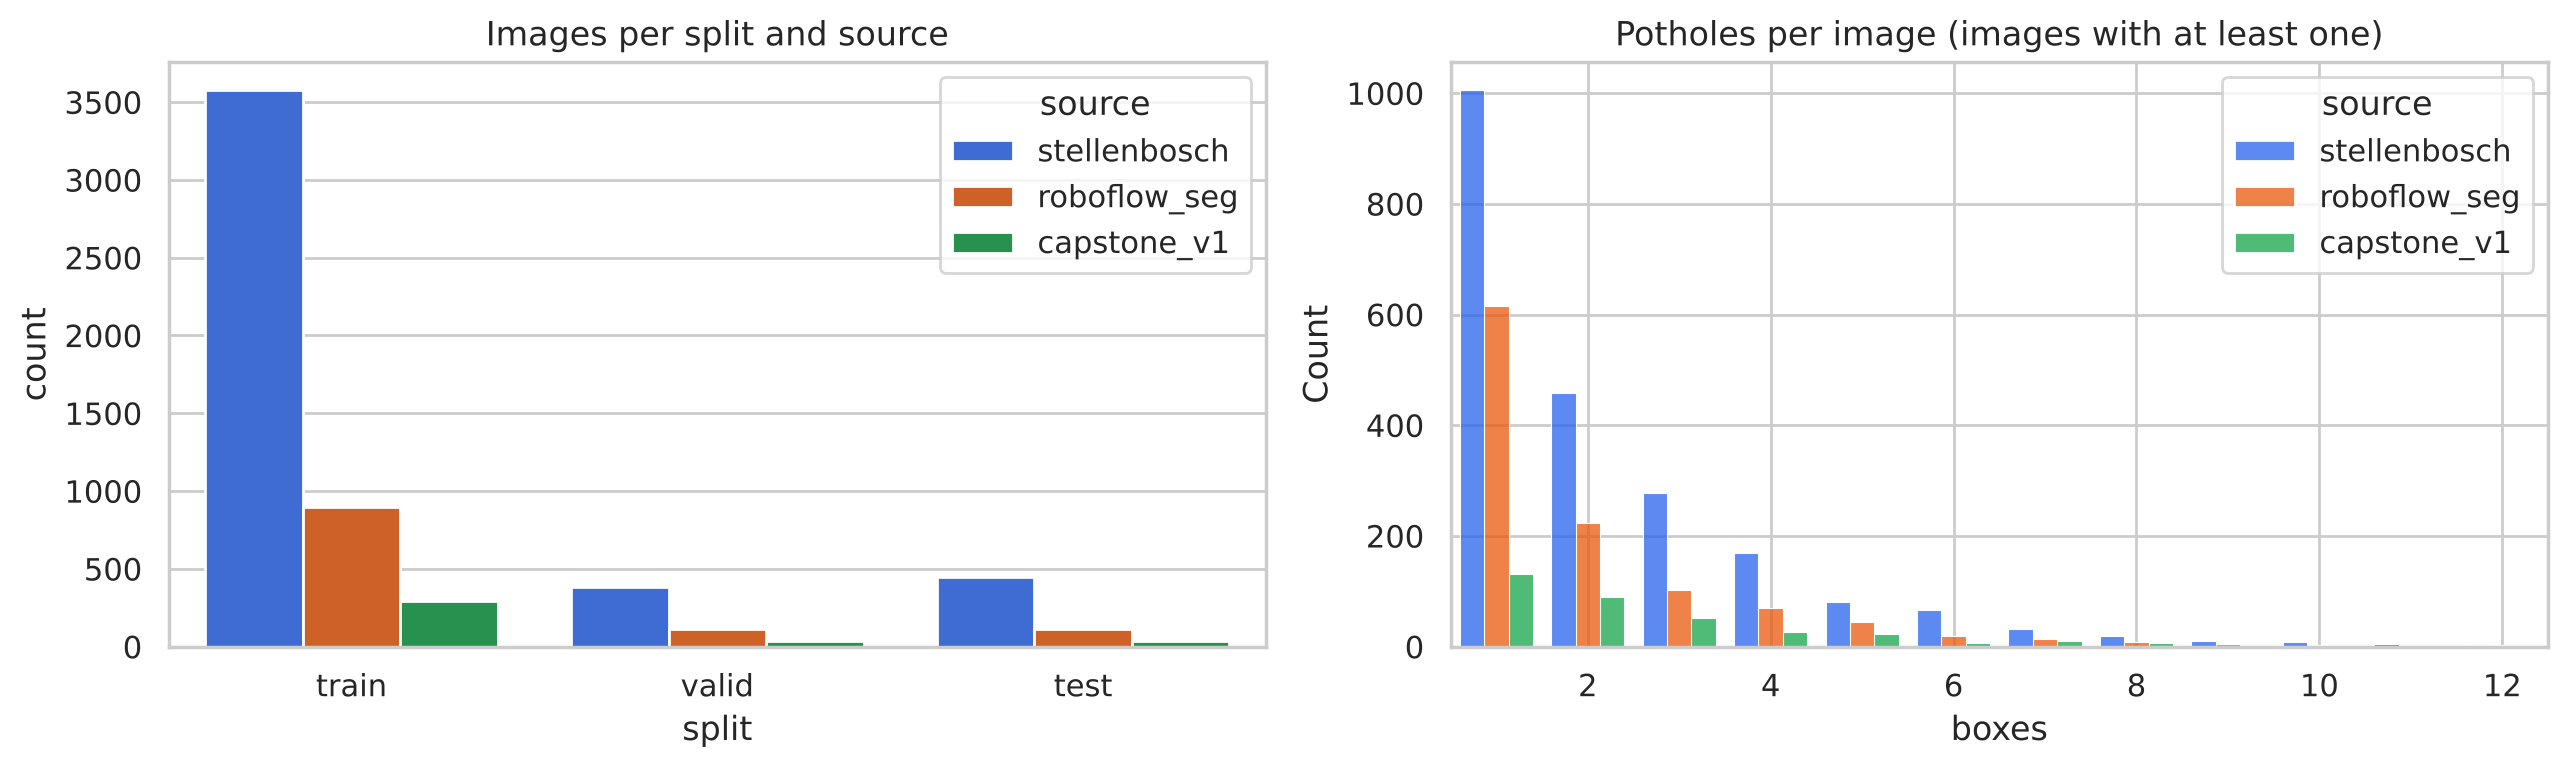

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=imgs, x="split", hue="source", hue_order=SOURCE_ORDER, palette=PALETTE, order=["train", "valid", "test"], ax=ax[0])
ax[0].set_title("Images per split and source")
pos = imgs[imgs.boxes > 0]
sns.histplot(data=pos, x="boxes", hue="source", hue_order=SOURCE_ORDER, palette=PALETTE, discrete=True, multiple="dodge",
             shrink=.8, ax=ax[1])
ax[1].set_xlim(0.5, 12.5); ax[1].set_title("Potholes per image (images with at least one)")
plt.tight_layout(); plt.show()


## 2. Pothole size at the model's input

COCO calls a box *small* below 32x32 px, *medium* up to 96x96, *large* above, measured on the image as given. RF-DETR squashes every image to a square before it sees it (560 px for the Base model the v1 capstone used, 384 to 576 for Nano to Medium). So the size that matters is the box size **after** that resize. A pothole 60 px wide in a 1600 px dashcam frame becomes 21 px at 560.

In [5]:
def size_at(res):
    sx = res / boxes.width
    sy = res / boxes.height
    return np.sqrt(boxes.w * sx * boxes.h * sy)

for res in (384, 560, 704):
    boxes[f"side_{res}"] = size_at(res)
    boxes[f"bin_{res}"] = pd.cut(boxes[f"side_{res}"], [0, 32, 96, 1e9], labels=["small", "medium", "large"])

tab = (boxes.groupby(["source", "bin_560"], observed=False).size().unstack()
       .pipe(lambda t: t.div(t.sum(axis=1), axis=0).mul(100).round(1)))
tab.columns = [f"% {c} at 560" for c in tab.columns]
tab


,% small at 560,% medium at 560,% large at 560
source,,,
capstone_v1,12.1,45.8,42.1
roboflow_seg,5.0,37.9,57.1
stellenbosch,98.0,2.0,0.0


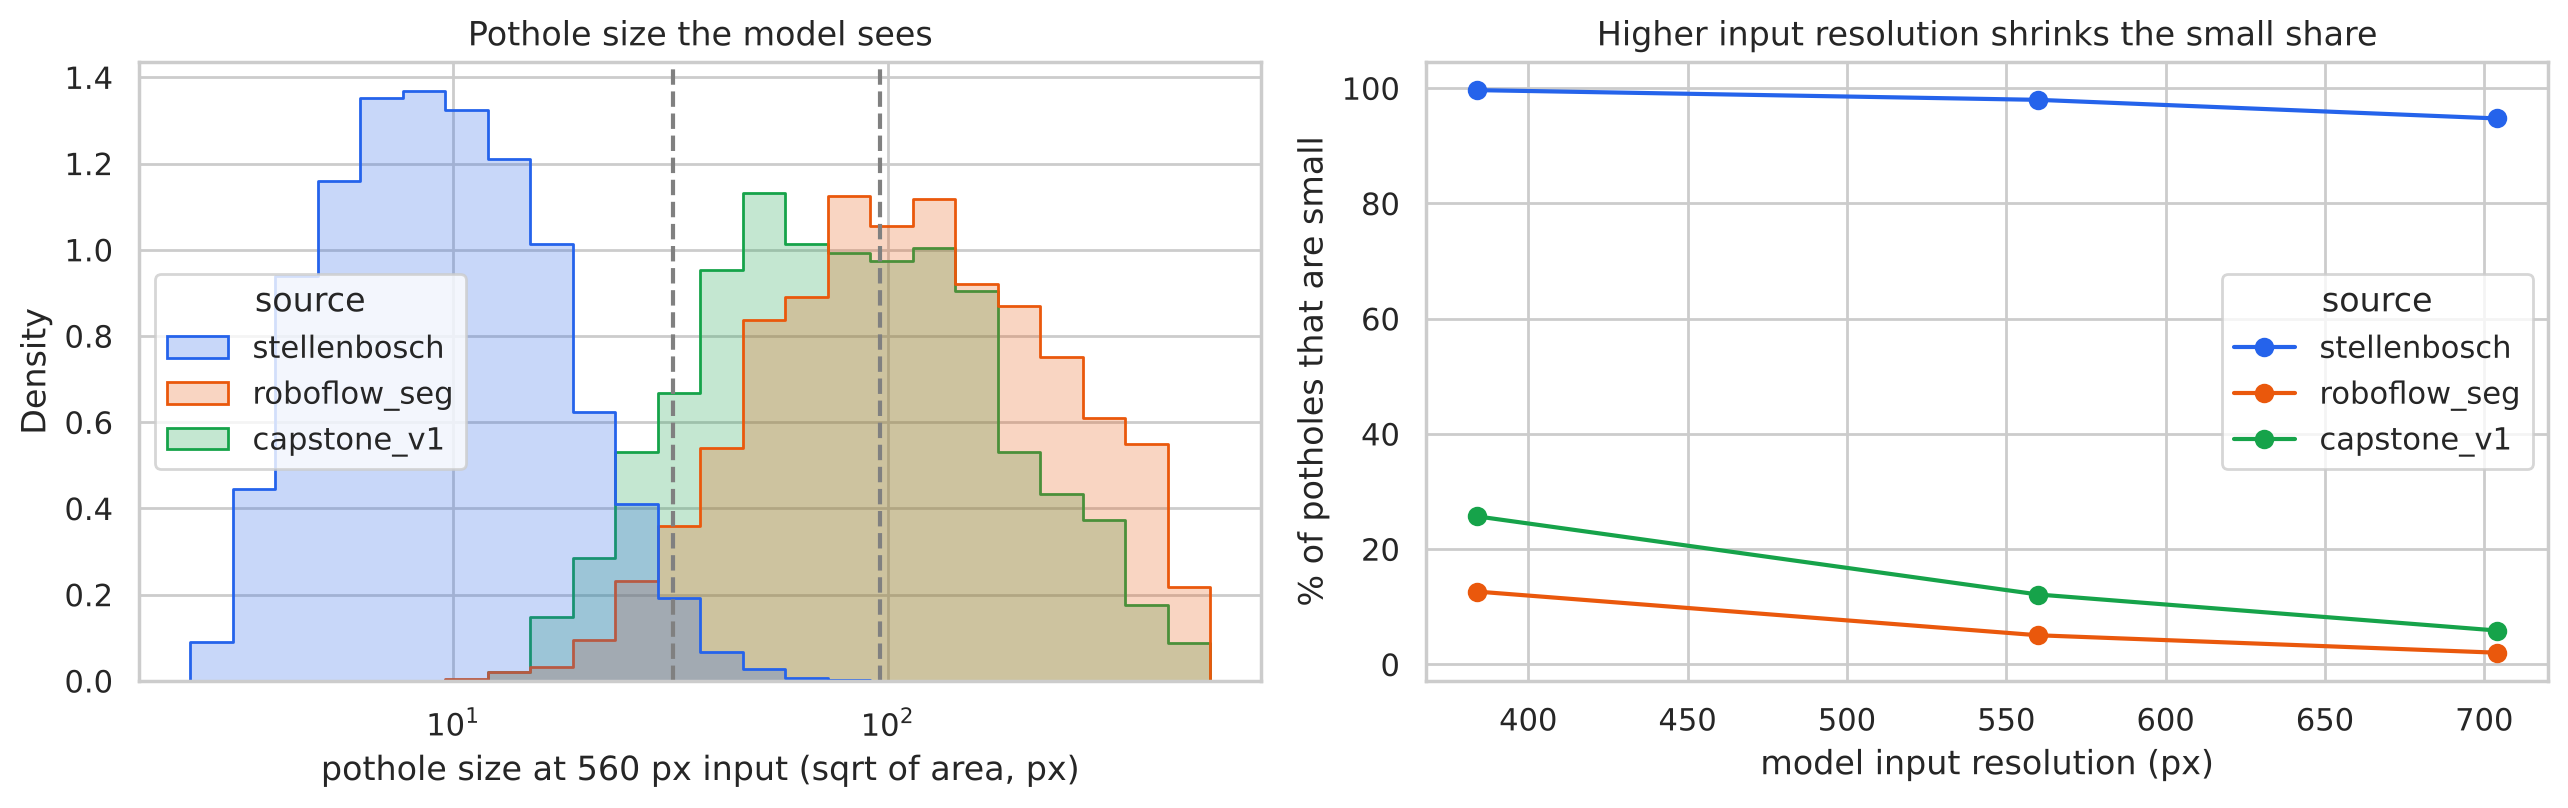

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(data=boxes, x="side_560", hue="source", hue_order=SOURCE_ORDER, palette=PALETTE, log_scale=True, element="step",
             stat="density", common_norm=False, ax=ax[0])
for v in (32, 96):
    ax[0].axvline(v, ls="--", c="grey")
ax[0].set_xlabel("pothole size at 560 px input (sqrt of area, px)"); ax[0].set_title("Pothole size the model sees")
share = pd.DataFrame({res: (boxes[f"side_{res}"] < 32).groupby(boxes.source).mean() * 100 for res in (384, 560, 704)})
share.T[SOURCE_ORDER].plot(marker="o", ax=ax[1], color=[PALETTE[s] for s in SOURCE_ORDER])
ax[1].set_xlabel("model input resolution (px)"); ax[1].set_ylabel("% of potholes that are small")
ax[1].set_title("Higher input resolution shrinks the small share")
plt.tight_layout(); plt.show()


## 3. Where potholes sit and what shape they are

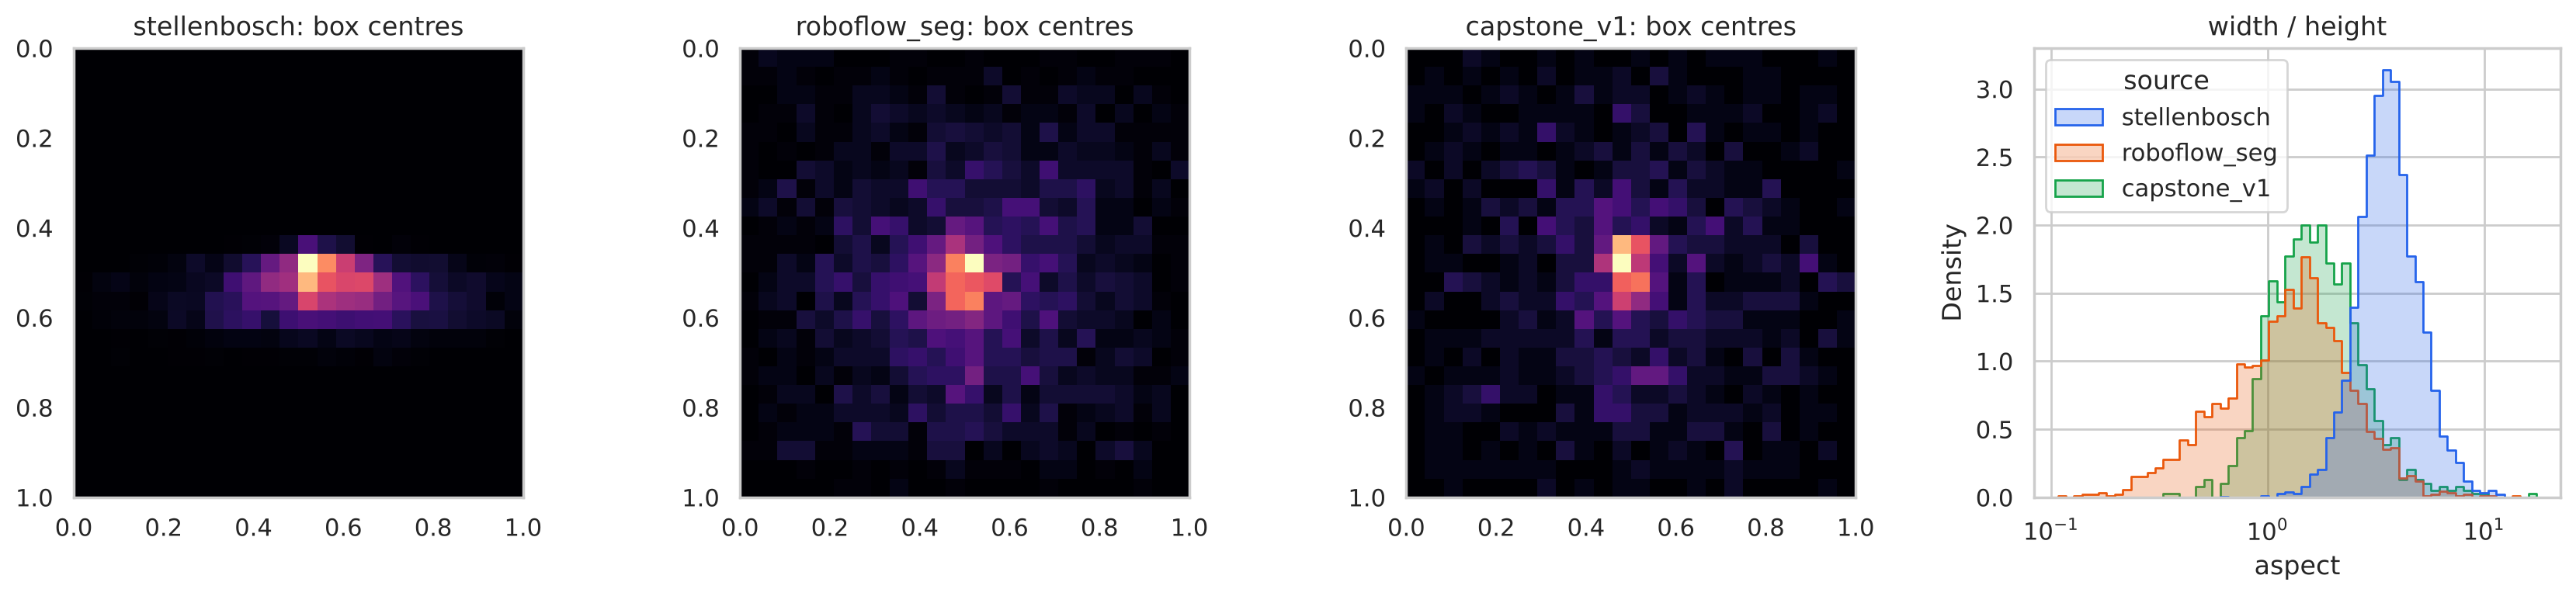

In [7]:
boxes["cx"] = (boxes.x + boxes.w / 2) / boxes.width
boxes["cy"] = (boxes.y + boxes.h / 2) / boxes.height
boxes["aspect"] = boxes.w / boxes.h
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, src in zip(axes, SOURCE_ORDER):
    d = boxes[boxes.source == src]
    ax.hist2d(d.cx, d.cy, bins=24, range=[[0, 1], [0, 1]], cmap="magma")
    ax.invert_yaxis(); ax.set_title(f"{src}: box centres"); ax.set_aspect("equal")
sns.histplot(data=boxes, x="aspect", hue="source", hue_order=SOURCE_ORDER, palette=PALETTE, log_scale=True, element="step",
             stat="density", common_norm=False, ax=axes[3])
axes[3].set_title("width / height")
plt.tight_layout(); plt.show()


## 4. Lighting, contrast and sharpness, and the Ugandan holdout

Three cheap image statistics on a sample of each source: brightness (mean grey level), contrast (standard deviation of grey levels) and sharpness (variance of the Laplacian; low means blur). The Ugandan Mapillary holdout is included to see how far it sits from the training sources.

In [8]:
import cv2
from tqdm.auto import tqdm

def image_stats(path):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (512, int(512 * g.shape[0] / g.shape[1])))
    return g.mean(), g.std(), cv2.Laplacian(g, cv2.CV_64F).var()

rows = []
rng = np.random.default_rng(0)
for src in SOURCE_ORDER:
    sub = imgs[imgs.source == src]
    for _, im in sub.sample(min(600, len(sub)), random_state=0).iterrows():
        rows.append((src, *image_stats(paths.image_path(im.file_name))))
ug_dir = paths.interim_dir("uganda_mapillary")
if (ug_dir / "coco.json").exists():
    ug = C.load(ug_dir / "coco.json")["images"]
    for im in [ug[i] for i in rng.choice(len(ug), min(600, len(ug)), replace=False)]:
        rows.append(("uganda_holdout", *image_stats(ug_dir / "images" / im["file_name"])))
stats = pd.DataFrame(rows, columns=["source", "brightness", "contrast", "sharpness"])
stats.groupby("source")[["brightness", "contrast", "sharpness"]].median().round(1)


,brightness,contrast,sharpness
source,,,
capstone_v1,132.7,40.9,883.5
roboflow_seg,128.7,43.8,770.2
stellenbosch,121.0,71.6,1612.7
uganda_holdout,124.3,62.2,1578.0


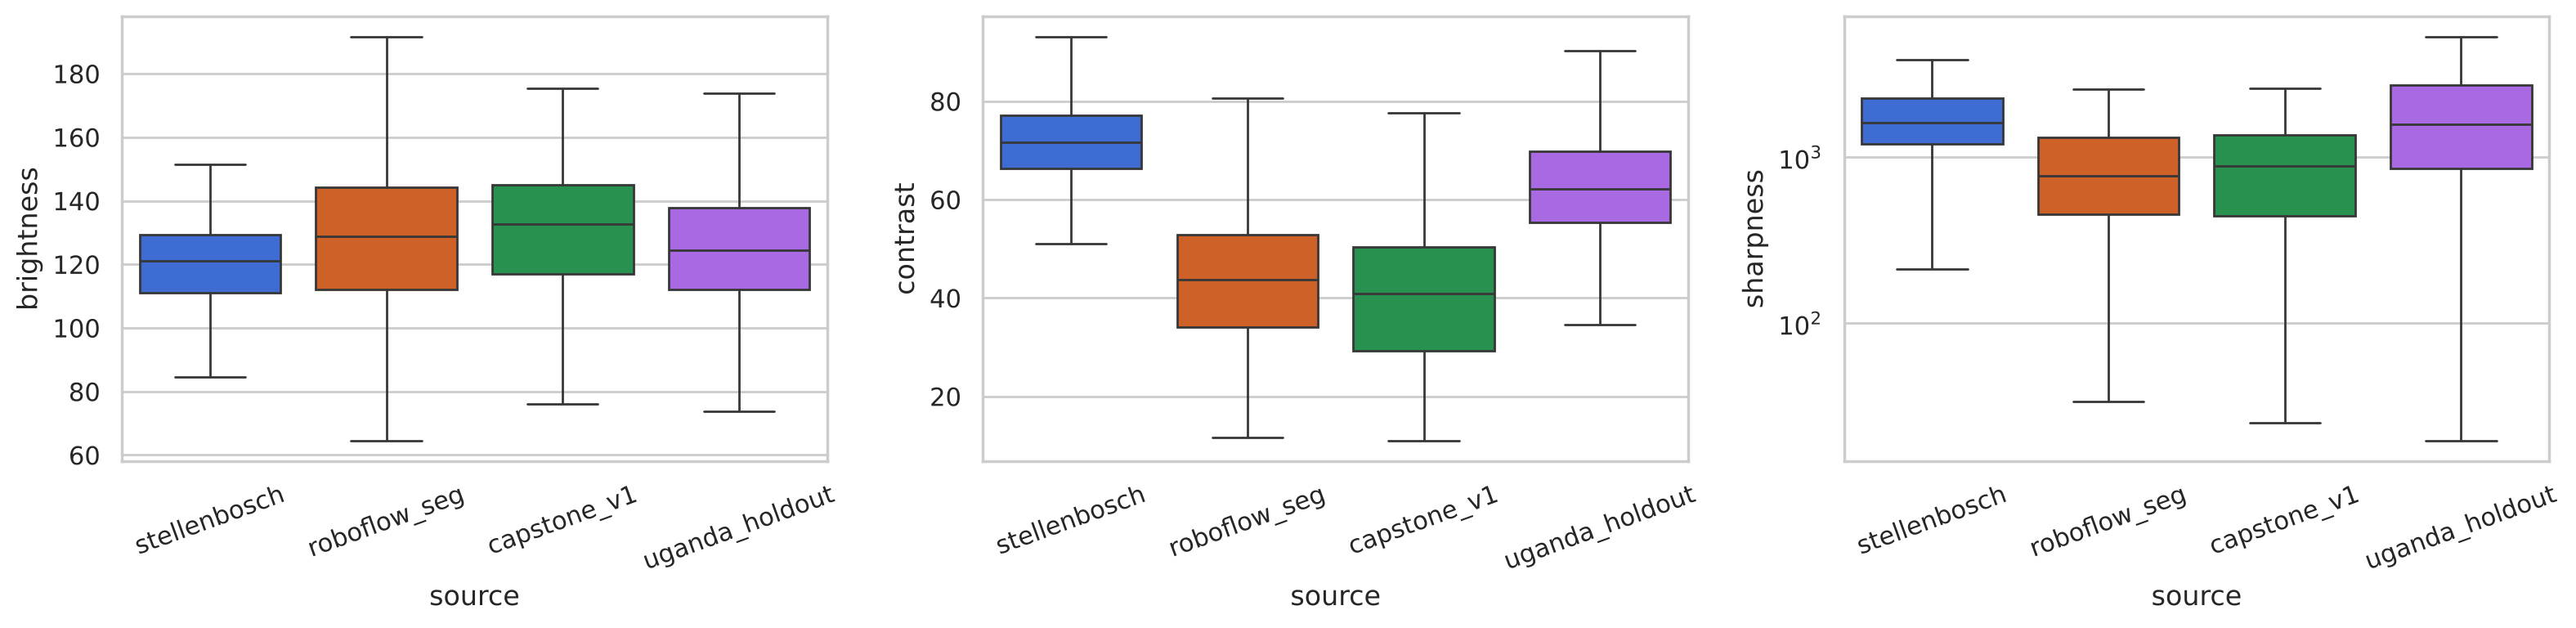

In [9]:
order = SOURCE_ORDER + (["uganda_holdout"] if "uganda_holdout" in set(stats.source) else [])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["brightness", "contrast", "sharpness"]):
    sns.boxplot(data=stats, x="source", y=col, order=order, ax=ax, showfliers=False, hue="source",
                palette=PALETTE, legend=False)
    ax.tick_params(axis="x", rotation=20)
axes[2].set_yscale("log")
plt.tight_layout(); plt.show()


## 5. Labels usable for the severity model

In [10]:
masks = boxes.groupby(["source", "mask"]).size().unstack(fill_value=0)
masks


mask,box,none,polygon
source,,,
capstone_v1,0,1040,0
roboflow_seg,1137,0,1343
stellenbosch,0,4922,0


## 6. The Ugandan holdout

,images,sequences,contributors,first,last
area,,,,,
entebbe,300,39,6,2019-12-14,2026-10-11
kampala,2000,605,37,2019-02-19,2026-10-11
lira,300,33,4,2021-05-13,2024-01-17
masaka,300,98,8,2019-12-29,2024-05-06
mbale,300,173,7,2019-09-27,2025-03-22


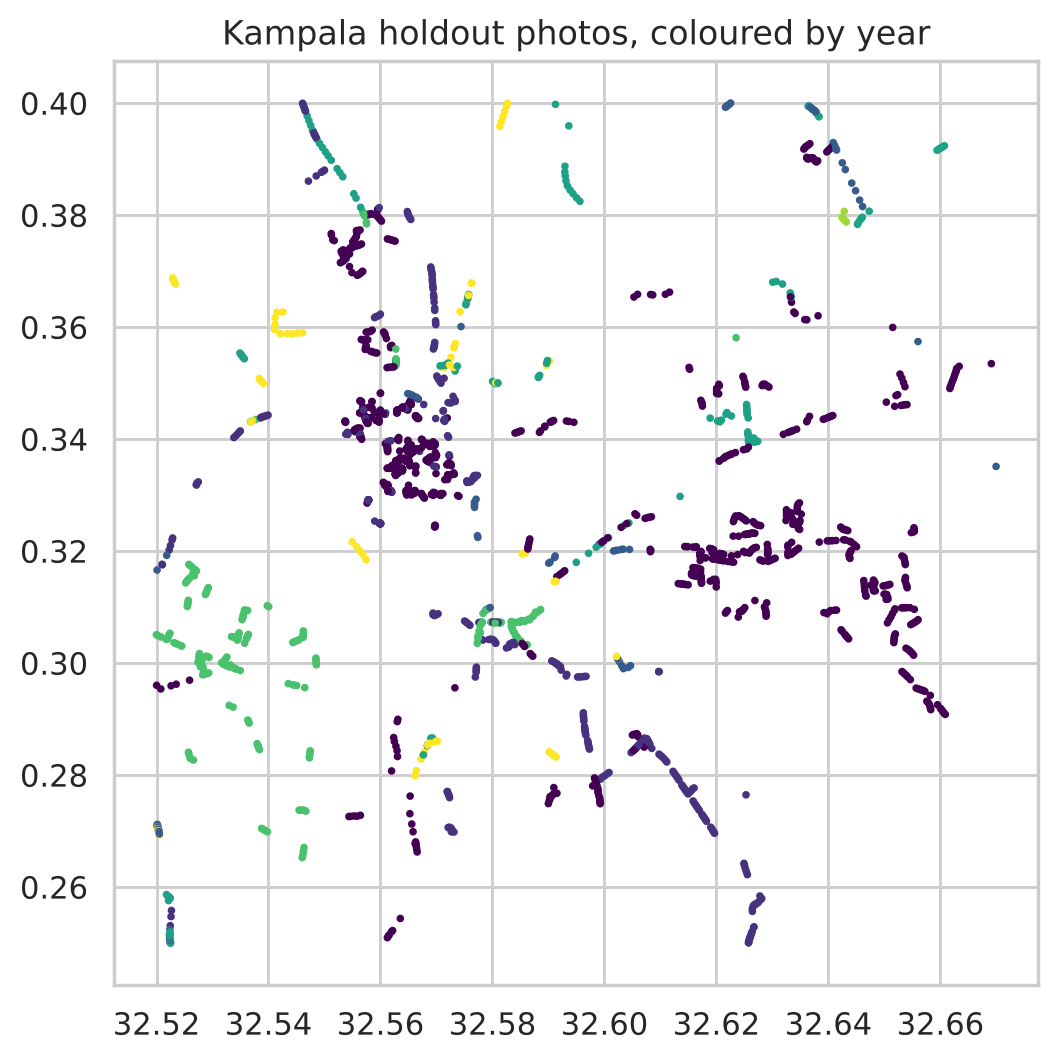

In [11]:
meta_path = ug_dir / "metadata.csv"
if meta_path.exists():
    meta = pd.read_csv(meta_path)
    display(meta.groupby("area").agg(images=("image_id", "size"), sequences=("sequence", "nunique"),
                                     contributors=("creator", "nunique"),
                                     first=("captured_at", lambda t: pd.to_datetime(t, unit="ms").min().date()),
                                     last=("captured_at", lambda t: pd.to_datetime(t, unit="ms").max().date())))
    fig, ax = plt.subplots(figsize=(6, 6))
    k = meta[meta.area == "kampala"]
    ax.scatter(k.lon, k.lat, s=3, c=pd.to_datetime(k.captured_at, unit="ms").dt.year, cmap="viridis")
    ax.set_title("Kampala holdout photos, coloured by year"); ax.set_aspect("equal")
    plt.show()


## What the data says, and what it changes

**1. The South African dashcam potholes are tiny to the model.** At a 560 px input, 98% of Stellenbosch potholes are *small* (under 32x32 px); their median size is about 9 px. Raising the input to 704 px barely helps (95% still small). The two Roboflow sources are the opposite: close-up phone photos where most potholes are medium or large. This explains the v1 model's 0.04 small-object AP better than any training setting: it had almost never seen a distant pothole.

*Decision:* report every result per source and per size, and test a **road-band crop** of the dashcam frames (experiment E4). Potholes sit in a narrow horizontal band (box centres at 45% to 60% of image height); cutting that band out before the square resize makes each pothole about twice as tall to the model. For the product, a pothole seen 40 m ahead is seen again 20 m ahead a second later, so the app only has to catch it once, at a usable size.

**2. Potholes are wide and flat in dashcam view.** Width / height peaks near 3.5 for Stellenbosch (road seen at a low angle) against about 1.3 for the phone photos. Two different viewing geometries live in one class.

**3. The Ugandan holdout looks like the dashcam data, not like the phone photos.** In contrast and sharpness, the Mapillary photos from Kampala and four other towns sit close to Stellenbosch and far from the Roboflow sets. Of the training sources, the African dashcam set is the most relevant one; without it, the model would mostly learn close-up photos.

**4. Only 1,343 potholes have real outlines.** All of them come from one source; the rest are boxes. The severity (segmentation) model is trained on that subset alone and is reported as a separate, smaller result.

**5. Pothole free images make up 39% of the data** (2,270 of 5,892), almost all dashcam frames. They teach the model what *not* to flag: shadows, patches, manholes and road markings.